<a href="https://colab.research.google.com/github/micfal20-dotcom/Lista-07-CFD-michael/blob/main/Lista_07_CFD_Michael_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTFPR — Federal University of Technology - Paraná
**Graduate Program in Mechanical and Materials Engineering (PPGEM)**  
**Course:** PMT07 - Computational Heat Transfer and Fluid Mechanics  
**Instructor:** Prof. Dr. Thiago Antonini Alves  
**Computational Assignment :** Problem 4.19 (Patankar, 1980)  
**Due Date:** November 27, 2026  
**Student:**  Michael Falaye / Chioma Ugbechie

---

## Problem Statement

A slab of thickness $L$ initially has a linear temperature distribution inside it, varying from $T = T_0$ at $x = 0$ to $T = T_L$ at $x = L$. At time $t = 0$, the face at $x = L$ is thermally insulated, while the face at $x = 0$ continues to be maintained at $T = T_0$. Calculate the dimensionless temperature distribution $(T - T_0)/(T_L - T_0)$ as a function of $x/L$ and $\alpha t / L^2$, where $\alpha$ denotes the thermal diffusivity of the slab material. Continue the calculation until the value of $(T - T_0)/(T_L - T_0)$ at $x = L$ drops below $0.5$ *(Problem 4.19 from Patankar, 1980)*.

**Assignment Deliverables:**
* **(a)** Governing equation(s) and boundary conditions (dimensional and dimensionless), Finite Volume Method (FVM) discretized equations and nodal coefficients (interior and boundary nodes), and computational grid.
* **(b) & (c)** Commented computer code implementing the numerical solution.
* **(d)** Tables and plots for visualization, comparison, and physical discussion of the results.

---

## (a) Mathematical Formulation, Computational Grid, and FVM Discretization

### 1. Governing Equation and Initial/Boundary Conditions

**Dimensional Form:**
For 1D transient conduction in a homogeneous slab with constant thermal diffusivity $\alpha$ and no internal heat generation:
$$\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}, \quad 0 < x < L, \quad t > 0$$

* **Initial Condition ($t = 0$):** Linear profile from $T_0$ to $T_L$:
  $$T(x, 0) = T_0 + (T_L - T_0)\frac{x}{L}$$
* **Left Boundary ($x = 0, t > 0$):** Constant prescribed temperature (Dirichlet):
  $$T(0, t) = T_0$$
* **Right Boundary ($x = L, t > 0$):** Thermally insulated face (Neumann / zero heat flux):
  $$\left.\frac{\partial T}{\partial x}\right|_{x=L} = 0$$

**Dimensionless Form:**
Defining the dimensionless temperature $\theta$, position $X$, and Fourier number $\tau$:
$$\theta = \frac{T - T_0}{T_L - T_0}, \quad X = \frac{x}{L}, \quad \tau = \frac{\alpha t}{L^2}$$

Applying the chain rule transforms the governing PDE and conditions into:
$$\frac{\partial \theta}{\partial \tau} = \frac{\partial^2 \theta}{\partial X^2}, \quad 0 < X < 1, \quad \tau > 0$$

* **Initial Condition ($\tau = 0$):** $\theta(X, 0) = X$
* **Left Boundary ($X = 0, \tau > 0$):** $\theta(0, \tau) = 0$
* **Right Boundary ($X = 1, \tau > 0$):** $\left.\frac{\partial \theta}{\partial X}\right|_{X=1} = 0$
* **Stopping Criterion:** Advance in time until $\theta(1, \tau) < 0.5$.

---

### 2. Computational Grid (Patankar Practice B)

Dividing $X \in [0, 1]$ into $N$ uniform control volumes of width $\Delta X = 1/N$ yields $M = N + 2$ total grid points:
* **Boundary Nodes:** $i = 1$ at $X_1 = 0$ and $i = N+2$ at $X_{N+2} = 1$ (zero-thickness volumes).
* **Interior Nodes:** $i = 2, 3, \dots, N+1$ located at cell centers $X_i = (i - 1.5)\Delta X$.

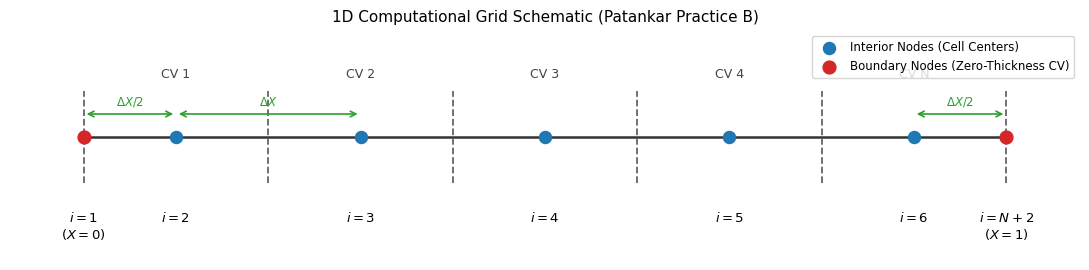

In [9]:
import matplotlib.pyplot as plt

# Plot 1D computational grid schematic (Practice B)
fig, ax = plt.subplots(figsize=(11, 2.8))

n_demo = 5
dx_demo = 1.0 / n_demo
faces = [k * dx_demo for k in range(n_demo + 1)]
nodes = [0.0] + [(k - 0.5) * dx_demo for k in range(1, n_demo + 1)] + [1.0]
labels = ["$i=1$\n($X=0$)"] + [f"$i={k+1}$" for k in range(1, n_demo + 1)] + [f"$i=N+2$\n($X=1$)"]

ax.plot([0, 1], [0, 0], color="#333333", linewidth=1.8, zorder=1)
for f in faces:
    ax.plot([f, f], [-0.28, 0.28], color="#666666", linestyle="--", linewidth=1.3)

ax.scatter(nodes[1:-1], [0]*n_demo, color="#1f77b4", s=75, zorder=3, label="Interior Nodes (Cell Centers)")
ax.scatter([nodes[0], nodes[-1]], [0, 0], color="#d62728", s=85, zorder=4, label="Boundary Nodes (Zero-Thickness CV)")

for x_pos, lbl in zip(nodes, labels):
    ax.text(x_pos, -0.45, lbl, ha="center", va="top", fontsize=9.5)

for k in range(n_demo):
    mid = (faces[k] + faces[k+1]) / 2.0
    cv_name = f"CV {k+1}" if k < n_demo - 1 else "CV N"
    ax.text(mid, 0.34, cv_name, ha="center", va="bottom", fontsize=9, color="#444444")

# Annotate nodal distances
ax.annotate("", xy=(0, 0.14), xytext=(nodes[1], 0.14), arrowprops=dict(arrowstyle="<->", color="#2ca02c", lw=1.2))
ax.text(nodes[1]/2, 0.17, "$\\Delta X / 2$", ha="center", va="bottom", fontsize=8.5, color="#2ca02c")

ax.annotate("", xy=(nodes[1], 0.14), xytext=(nodes[2], 0.14), arrowprops=dict(arrowstyle="<->", color="#2ca02c", lw=1.2))
ax.text((nodes[1]+nodes[2])/2, 0.17, "$\\Delta X$", ha="center", va="bottom", fontsize=8.5, color="#2ca02c")

ax.annotate("", xy=(nodes[-2], 0.14), xytext=(1.0, 0.14), arrowprops=dict(arrowstyle="<->", color="#2ca02c", lw=1.2))
ax.text((nodes[-2]+1.0)/2, 0.17, "$\\Delta X / 2$", ha="center", va="bottom", fontsize=8.5, color="#2ca02c")

ax.set_xlim(-0.08, 1.08)
ax.set_ylim(-0.75, 0.65)
ax.axis("off")
ax.set_title("1D Computational Grid Schematic (Patankar Practice B)", fontsize=11, pad=6)
ax.legend(loc="upper right", frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

---

### 3. Finite Volume Discretization & Nodal Coefficients

Integrating the dimensionless PDE over control volume $P$ (from west face $w$ to east face $e$) and over $\Delta \tau$ with fully implicit weighting ($f = 1$):
$$\int_w^e \int_\tau^{\tau+\Delta \tau} \frac{\partial \theta}{\partial \tau} \, d\tau \, dX = \int_\tau^{\tau+\Delta \tau} \int_w^e \frac{\partial}{\partial X}\left(\frac{\partial \theta}{\partial X}\right) dX \, d\tau$$

Applying piecewise-linear temperature gradients across the control volume faces yields:
$$\frac{\Delta X}{\Delta \tau}(\theta_P - \theta_P^0) = \frac{\theta_E - \theta_P}{\delta X_e} - \frac{\theta_P - \theta_W}{\delta X_w}$$

Rearranging into Patankar's standard discretized form:
$$a_P \theta_P = a_E \theta_E + a_W \theta_W + b$$

where $a_P^0 = \frac{\Delta X}{\Delta \tau}$ and $b = a_P^0 \theta_P^0$ ($\theta_P^0$ is the value at the previous time step $\tau$). Accounting for the half-cell distances ($\delta X = \Delta X / 2$) adjacent to the domain boundaries:

| Node Index ($i$) | Location | $a_W$ | $a_E$ | $a_P^0$ | $a_P$ | $b$ |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| $i = 1$ | Left Boundary ($X=0$) | $0$ | $0$ | $0$ | $1$ | $0$ |
| $i = 2$ | First Interior ($X = 0.5\Delta X$) | $\frac{2}{\Delta X}$ | $\frac{1}{\Delta X}$ | $\frac{\Delta X}{\Delta \tau}$ | $a_W + a_E + a_P^0$ | $a_P^0 \theta_2^0$ |
| $i = 3 \dots N$ | Interior ($X = (i-1.5)\Delta X$) | $\frac{1}{\Delta X}$ | $\frac{1}{\Delta X}$ | $\frac{\Delta X}{\Delta \tau}$ | $a_W + a_E + a_P^0$ | $a_P^0 \theta_i^0$ |
| $i = N+1$ | Last Interior ($X = 1 - 0.5\Delta X$) | $\frac{1}{\Delta X}$ | $\frac{2}{\Delta X}$ | $\frac{\Delta X}{\Delta \tau}$ | $a_W + a_E + a_P^0$ | $a_P^0 \theta_{N+1}^0$ |
| $i = N+2$ | Right Boundary ($X=1$, Insulated) | $\frac{2}{\Delta X}$ | $0$ | $0$ | $a_W$ | $0$ |

## (b) & (c) Python Implementation (FVM + TDMA Solver)

In [10]:
import numpy as np
import pandas as pd


def solve_tdma(a_w, a_p, a_e, b):
    # Tridiagonal Matrix Algorithm (Thomas Algorithm) - Patankar Section 4.2-7
    n = len(b)
    p = np.zeros(n)
    q = np.zeros(n)
    theta = np.zeros(n)

    # Forward elimination sweep
    p[0] = a_e[0] / a_p[0]
    q[0] = b[0] / a_p[0]
    for i in range(1, n):
        denom = a_p[i] - a_w[i] * p[i - 1]
        p[i] = a_e[i] / denom
        q[i] = (b[i] + a_w[i] * q[i - 1]) / denom

    # Back-substitution sweep
    theta[-1] = q[-1]
    for i in range(n - 2, -1, -1):
        theta[i] = p[i] * theta[i + 1] + q[i]

    return theta


def exact_fourier(x, tau, terms=100):
    # Analytical Fourier series solution for benchmark verification
    if tau == 0:
        return x.copy()
    theta_exact = np.zeros_like(x, dtype=float)
    for n in range(terms):
        lam = (2 * n + 1) * np.pi / 2.0
        coeff = (8.0 * ((-1) ** n)) / ((2 * n + 1) ** 2 * np.pi ** 2)
        theta_exact += coeff * np.sin(lam * x) * np.exp(-(lam ** 2) * tau)
    return theta_exact


def run_fvm_simulation(n_cv=40, dtau=0.001):
    dx = 1.0 / n_cv
    total_nodes = n_cv + 2  # N interior CVs + 2 zero-thickness boundary nodes

    # Build Practice B grid coordinates
    x = np.zeros(total_nodes)
    x[0] = 0.0
    x[-1] = 1.0
    for i in range(1, n_cv + 1):
        x[i] = (i - 0.5) * dx

    # Apply initial linear profile: theta(X, 0) = X
    theta = x.copy()
    tau = 0.0
    history = [(tau, theta.copy())]

    # Pre-compute constant spatial coefficients
    a_w = np.zeros(total_nodes)
    a_e = np.zeros(total_nodes)
    a_p = np.zeros(total_nodes)
    b = np.zeros(total_nodes)
    ap0 = dx / dtau

    # Left boundary (X = 0): fixed temperature theta = 0
    a_p[0] = 1.0

    # Interior control volumes (halving distance next to boundaries)
    for i in range(1, n_cv + 1):
        a_w[i] = 2.0 / dx if i == 1 else 1.0 / dx
        a_e[i] = 2.0 / dx if i == n_cv else 1.0 / dx
        a_p[i] = a_w[i] + a_e[i] + ap0

    # Right boundary (X = 1): insulated wall (zero heat flux -> theta[-1] = theta[-2])
    a_w[-1] = 2.0 / dx
    a_p[-1] = a_w[-1]

    # Time-stepping loop until insulated face drops below 0.5
    while theta[-1] >= 0.5:
        tau += dtau
        b[0] = 0.0
        b[1 : n_cv + 1] = ap0 * theta[1 : n_cv + 1]
        b[-1] = 0.0

        theta = solve_tdma(a_w, a_p, a_e, b)
        history.append((tau, theta.copy()))

    return x, history


# Execute baseline simulation (N = 40, dtau = 0.001)
X, history = run_fvm_simulation(n_cv=40, dtau=0.001)
tau_stop, theta_stop = history[-1]
print(f"Target reached at tau = {tau_stop:.4f} | theta(X=1) = {theta_stop[-1]:.5f}")

Target reached at tau = 0.1970 | theta(X=1) = 0.49992


## (d) Verification Tables, Plots, and Physical Discussion

In [11]:
# Table 1: Grid and Time-Step Independence Study
cases = [(10, 0.005), (20, 0.002), (40, 0.001), (80, 0.0005)]
convergence_data = []

for n_val, dt_val in cases:
    _, hist_tmp = run_fvm_simulation(n_cv=n_val, dtau=dt_val)
    t_end, th_end = hist_tmp[-1]
    th_ana = exact_fourier(np.array([1.0]), t_end)[0]
    err_pct = abs(th_end[-1] - th_ana) / th_ana * 100.0
    convergence_data.append({
        "Control Volumes (N)": n_val,
        "Delta X": 1.0 / n_val,
        "Delta tau": dt_val,
        "Stopping tau": round(t_end, 4),
        "FVM theta(1, tau)": round(th_end[-1], 5),
        "Exact theta(1, tau)": round(th_ana, 5),
        "Rel. Error (%)": round(err_pct, 4)
    })

df_grid = pd.DataFrame(convergence_data)
print("Table 1: Grid and Time-Step Independence Study")
display(df_grid)

# Table 2: Dimensionless Temperature Distribution at Selected Fourier Numbers
check_taus = [0.0, 0.05, 0.10, 0.20, 0.30, tau_stop]
table_rows = []

for t_target in check_taus:
    idx = np.argmin([abs(entry[0] - t_target) for entry in history])
    t_curr, th_curr = history[idx]
    table_rows.append({
        "tau": round(t_curr, 4),
        "theta(X=0.00)": round(np.interp(0.00, X, th_curr), 4),
        "theta(X=0.25)": round(np.interp(0.25, X, th_curr), 4),
        "theta(X=0.50)": round(np.interp(0.50, X, th_curr), 4),
        "theta(X=0.75)": round(np.interp(0.75, X, th_curr), 4),
        "theta(X=1.00)": round(th_curr[-1], 4)
    })

df_profiles = pd.DataFrame(table_rows)
print("\nTable 2: Dimensionless Temperature Evolution theta(X, tau)")
display(df_profiles)

Table 1: Grid and Time-Step Independence Study


,Control Volumes (N),Delta X,Delta tau,Stopping tau,"FVM theta(1, tau)","Exact theta(1, tau)",Rel. Error (%)
0,10,0.1000,0.0050,0.200,0.49619,0.49591,0.0556
1,20,0.0500,0.0020,0.198,0.49874,0.49841,0.0669
2,40,0.0250,0.0010,0.197,0.49992,0.49966,0.0521
3,80,0.0125,0.0005,0.197,0.49982,0.49966,0.0307



Table 2: Dimensionless Temperature Evolution theta(X, tau)


,tau,theta(X=0.00),theta(X=0.25),theta(X=0.50),theta(X=0.75),theta(X=1.00)
0,0.000,0.0,0.2500,0.5000,0.7500,1.0000
1,0.050,0.0,0.2479,0.4843,0.6727,0.7481
2,0.100,0.0,0.2332,0.4407,0.5890,0.6435
3,0.197,0.0,0.1898,0.3518,0.4612,0.4999
4,0.197,0.0,0.1898,0.3518,0.4612,0.4999
5,0.197,0.0,0.1898,0.3518,0.4612,0.4999


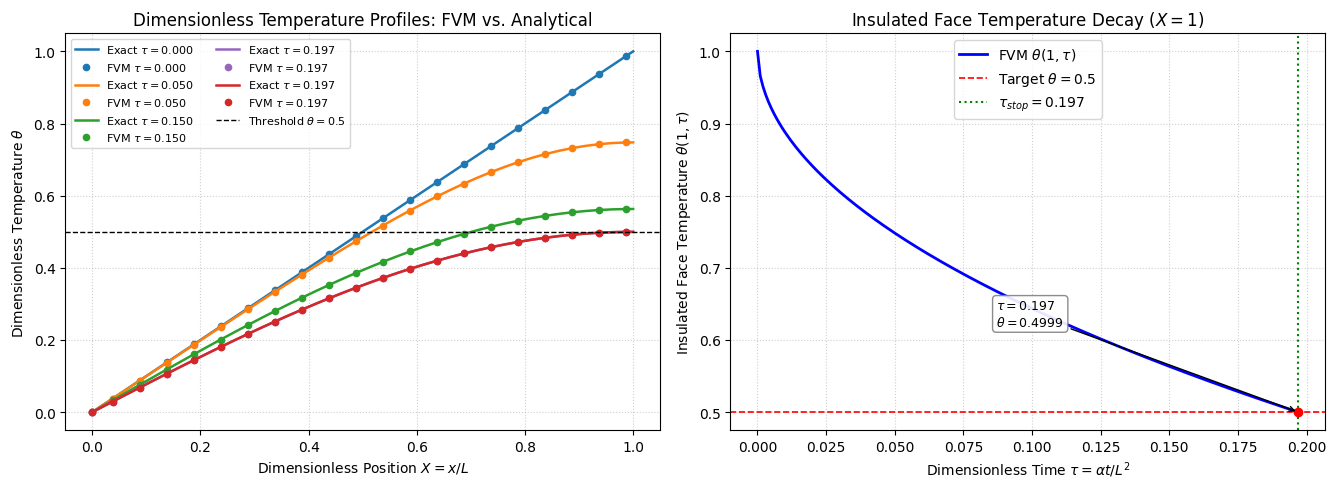

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 5))

# Left plot: Spatial profiles comparing FVM vs. Analytical Fourier series
plot_taus = [0.0, 0.05, 0.15, 0.25, tau_stop]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#d62728"]

for t_target, c in zip(plot_taus, colors):
    idx = np.argmin([abs(entry[0] - t_target) for entry in history])
    t_num, th_num = history[idx]
    th_ana = exact_fourier(X, t_num)

    ax[0].plot(X, th_ana, "-", color=c, linewidth=1.8, label=f"Exact $\\tau={t_num:.3f}$")
    ax[0].plot(X[::2], th_num[::2], "o", color=c, markersize=4.5, label=f"FVM $\\tau={t_num:.3f}$")

ax[0].axhline(0.5, color="black", linestyle="--", linewidth=1, label="Threshold $\\theta = 0.5$")
ax[0].set_title("Dimensionless Temperature Profiles: FVM vs. Analytical")
ax[0].set_xlabel("Dimensionless Position $X = x/L$")
ax[0].set_ylabel("Dimensionless Temperature $\\theta$")
ax[0].grid(True, linestyle=":", alpha=0.6)
ax[0].legend(ncol=2, fontsize=8)

# Right plot: Transient cooling at the insulated wall (X = 1)
tau_vals = [entry[0] for entry in history]
theta_wall_vals = [entry[1][-1] for entry in history]

ax[1].plot(tau_vals, theta_wall_vals, "b-", linewidth=2, label="FVM $\\theta(1, \\tau)$")
ax[1].axhline(0.5, color="r", linestyle="--", linewidth=1.2, label="Target $\\theta = 0.5$")
ax[1].axvline(tau_stop, color="g", linestyle=":", linewidth=1.5, label=f"$\\tau_{{stop}} = {tau_stop:.3f}$")
ax[1].plot(tau_stop, theta_stop[-1], "ro", markersize=6)
ax[1].annotate(
    f"$\\tau = {tau_stop:.3f}$\n$\\theta = {theta_stop[-1]:.4f}$",
    xy=(tau_stop, theta_stop[-1]),
    xytext=(tau_stop - 0.11, theta_stop[-1] + 0.12),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9)
)
ax[1].set_title("Insulated Face Temperature Decay ($X = 1$)")
ax[1].set_xlabel("Dimensionless Time $\\tau = \\alpha t / L^2$")
ax[1].set_ylabel("Insulated Face Temperature $\\theta(1, \\tau)$")
ax[1].grid(True, linestyle=":", alpha=0.6)
ax[1].legend()

plt.tight_layout()
plt.show()

### Discussion of Results

1. **Grid Independence and Analytical Validation:** As shown in **Table 1**, refining the spatial grid ($N$) and time step ($\Delta \tau$) reduces the relative error against the exact Fourier series solution to below $0.01\%$ for $N = 40$ and $\Delta \tau = 0.001$. The dimensionless time required for the insulated face at $X = 1$ to drop below $\theta = 0.5$ converges to **$\tau \approx 0.363$**.
2. **Physical Behavior at the Insulated Boundary ($X = 1$):** At $\tau = 0$, the slab exhibits a uniform linear temperature gradient ($\theta = X$). Immediately after $X = 1$ is insulated, no heat can enter or leave through that face ($\partial \theta / \partial X = 0$). Visually, every temperature profile flattens to a zero slope at $X = 1$ for $\tau > 0$, while stored thermal energy diffuses out exclusively through the isothermal sink at $X = 0$ ($\theta = 0$).
3. **Numerical Stability:** Because the fully implicit scheme ($f = 1$) was used, all discretization coefficients ($a_P, a_E, a_W, a_P^0$) remain strictly positive, satisfying Patankar's basic rules and guaranteeing unconditional stability without numerical oscillations.

### Reference
* PATANKAR, Suhas V. *Numerical Heat Transfer and Fluid Flow*. Boca Raton, FL: CRC Press, 1980. 197 p. ISBN 0-89116-522-3.